# Notebook 4 -- SINDy : la dynamique latente ne s'identifie pas sur ces donnees
### Un resultat negatif reproduit avec deux bibliotheques de fonctions differentes

> **Note de provenance.** Ce notebook fait partie d'une reorganisation en 9 notebooks de quatre
> notebooks de recherche originaux (`SSI_SINDy_missing_sensor_reconstruction_1.ipynb`,
> `01_SSI_SINDy_EKF_reconstruction_capteur_manquant.ipynb`,
> `02_XGBoost_reconstruction_capteur_manquant_evaluation.ipynb`, `dictionary_learning.ipynb`).
> Le code et les sorties (chiffres, figures, journaux d'entrainement) presentes ici sont repris
> **a l'identique** des executions originales, realisees par l'auteur sur des donnees qui ne sont
> pas disponibles dans l'environnement ou cette synthese a ete redigee. Aucun resultat n'a ete
> recalcule, ni invente : quand une information n'etait pas determinable a partir des notebooks
> fournis, cela est signale explicitement plutot que comble. Ce notebook n'est donc pas concu pour
> etre re-execute isolement de haut en bas ; il documente et interprete des resultats deja obtenus.

## Objectif

Repondre a la question laissee ouverte par le notebook 3 : les correlations statistiques fortes
entre capteurs (notebook 2) et les motifs recurrents captures par le Dictionary Learning
(notebook 3) traduisent-ils une **dynamique physique ou quasi-physique identifiable**, ou restent-ils
de simples co-occurrences statistiques ? SINDy (*Sparse Identification of Nonlinear Dynamical
Systems*) est concu precisement pour repondre a ce type de question : il cherche une equation
differentielle parcimonieuse dx/dt = Theta(x) . Xi decrivant l'evolution d'un etat latent x,
plutot qu'une simple relation statique entre observations.

## Motivation

Une correlation forte entre deux capteurs ne prouve pas l'existence d'une relation physique
causale entre eux. Pour aller au-dela de ce que la regression du notebook 2 peut offrir, il faut
un modele qui identifie explicitement une loi d'evolution temporelle, verifiable independamment
(stabilite en simulation libre, coherence des derivees), plutot qu'une simple courbe de meilleur
ajustement instantane.

## Hypothese

L'etat latent extrait par SSI (identification en sous-espace stochastique, presentee en detail au
notebook 5) obeit a une dynamique continue dx/dt = f(x), ou f peut etre approximee par une
combinaison parcimonieuse de fonctions polynomiales (et, dans une variante enrichie, trigonometriques)
de x, identifiee par regression sequentiellement seuillee (STLSQ).

## Methodologie

SINDy est applique non pas directement aux signaux capteurs, mais a la trajectoire d'etat latent
x(t) estimee par SSI (huit etats, ordre choisi par Validation -- voir notebook 5 pour le detail de
cette etape amont). Deux configurations de bibliotheque de fonctions candidates ont ete testees
dans le corpus original, sur les memes etats latents SSI (jeu de donnees `preprocessed_data.csv`
pour la premiere, `preprocessed_data1.csv` pour la seconde -- voir notebook 1 pour la difference
entre les deux) :

1. **Bibliotheque simple** (degre polynomial 2, sans termes trigonometriques), seuil de sparsite
   choisi parmi {0,01 ; 0,02 ; 0,05 ; 0,1 ; 0,2} par minimisation de la RMSE de simulation libre
   sur Validation.
2. **Bibliotheque enrichie** ("version amelioree" du corpus original), degre polynomial 2 ou 3,
   avec ajout de termes sin/cos, et un test de stabilite explicite (simulation libre courte,
   detection des etats "hors domaine").

### Tentative 1 -- bibliotheque polynomiale simple

In [32]:

# ============================================================
# SINDy — implémentation autonome
# numpy / scipy uniquement
# ============================================================

from itertools import combinations_with_replacement

import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from pandas.api.types import is_datetime64_any_dtype


# ============================================================
# 1. ESTIMATION DU PAS DE TEMPS
# ============================================================

# Vérification de l'existence de la colonne temporelle
assert TIME_COLUMN in df.columns, (
    f"TIME_COLUMN='{TIME_COLUMN}' absent des colonnes : "
    f"{list(df.columns)}"
)

# Conversion robuste en datetime
# Cela fonctionne également avec datetime64[ns, UTC]
if not is_datetime64_any_dtype(df[TIME_COLUMN]):
    df[TIME_COLUMN] = pd.to_datetime(
        df[TIME_COLUMN],
        errors="coerce",
        utc=True
    )

# Vérifier qu'il n'y a pas de dates invalides
assert df[TIME_COLUMN].notna().all(), (
    f"La colonne {TIME_COLUMN} contient des dates invalides."
)

# Calcul du pas de temps
time_diff = df[TIME_COLUMN].diff().dropna()

if len(time_diff) > 0:

    # Conversion en secondes
    DT_APPX_VALUES = time_diff.dt.total_seconds()

    # On utilise la médiane pour être robuste aux éventuelles
    # petites irrégularités du sampling
    DT_APPROX = DT_APPX_VALUES.median()

else:
    DT_APPROX = 1.0


# Sécurité
if DT_APPROX <= 0 or not np.isfinite(DT_APPROX):
    print(
        "Attention : pas de temps invalide. "
        "Utilisation de dt = 1.0 seconde."
    )
    DT_APPROX = 1.0


print(f"Pas de temps estimé (dt) : {DT_APPROX:.6f} s")


# ============================================================
# 2. ESTIMATION DES ÉTATS SSI
# ============================================================

X_val_hat = ssi_estimate_states(
    Y_val_full,
    C_ssi,
    A,
    SSI_BLOCK_ROWS
)


# ============================================================
# 3. BIBLIOTHÈQUE POLYNOMIALE
# ============================================================

def build_polynomial_library(X, degree, feature_names):
    """
    Construit la bibliothèque :

        Theta(X) = [1, x1, x2, ..., x1², x1*x2, ...]

    jusqu'au degré demandé.

    Parameters
    ----------
    X : ndarray
        Matrice des états, shape (n_samples, n_states)

    degree : int
        Degré polynomial, généralement 1 ou 2.

    feature_names : list
        Noms des états.

    Returns
    -------
    Theta : ndarray
        Bibliothèque des fonctions candidates.

    names : list
        Noms des fonctions candidates.
    """

    n_samples, n_features = X.shape

    cols = [np.ones(n_samples)]
    names = ["1"]

    # --------------------------------------------------------
    # Termes linéaires
    # --------------------------------------------------------

    for i in range(n_features):
        cols.append(X[:, i])
        names.append(feature_names[i])

    # --------------------------------------------------------
    # Termes quadratiques
    # --------------------------------------------------------

    if degree >= 2:

        for i, j in combinations_with_replacement(
            range(n_features), 2
        ):

            cols.append(X[:, i] * X[:, j])

            if i == j:
                names.append(
                    f"{feature_names[i]}^2"
                )
            else:
                names.append(
                    f"{feature_names[i]} {feature_names[j]}"
                )

    Theta = np.column_stack(cols)

    return Theta, names


# ============================================================
# 4. STLSQ
# ============================================================

def stlsq(
    Theta,
    Xdot,
    threshold,
    alpha,
    max_iter=20
):
    """
    Sequentially Thresholded Least Squares (STLSQ).

    Régression Ridge suivie d'un seuillage itératif
    des coefficients faibles.
    """

    n_features_lib = Theta.shape[1]
    n_states = Xdot.shape[1]

    Xi = np.zeros(
        (n_features_lib, n_states)
    )

    # --------------------------------------------------------
    # Régression Ridge initiale
    # --------------------------------------------------------

    A_ridge = (
        Theta.T @ Theta
        + alpha * np.eye(n_features_lib)
    )

    b_ridge = Theta.T @ Xdot

    Xi = np.linalg.solve(
        A_ridge,
        b_ridge
    )

    # --------------------------------------------------------
    # STLSQ pour chaque équation
    # --------------------------------------------------------

    for k in range(n_states):

        active = np.ones(
            n_features_lib,
            dtype=bool
        )

        for _ in range(max_iter):

            if active.sum() == 0:
                break

            # Coefficients trop petits
            small = (
                np.abs(Xi[active, k])
                < threshold
            )

            if not small.any():
                break

            idx_active = np.where(active)[0]

            active[
                idx_active[small]
            ] = False

            # Aucun terme conservé
            if active.sum() == 0:

                Xi[:, k] = 0.0

                break

            # Régression uniquement sur les termes actifs
            Theta_active = Theta[:, active]

            A_active = (
                Theta_active.T
                @ Theta_active
                + alpha * np.eye(active.sum())
            )

            b_active = (
                Theta_active.T
                @ Xdot[:, k]
            )

            Xi[:, k] = 0.0

            Xi[active, k] = np.linalg.solve(
                A_active,
                b_active
            )

    return Xi


# ============================================================
# 5. MODÈLE SINDy
# ============================================================

class SimpleSINDy:
    """
    Modèle SINDy minimal :

        dx/dt = Theta(x) @ Xi
    """

    def __init__(
        self,
        degree=2,
        threshold=0.05,
        alpha=0.05
    ):

        self.degree = degree
        self.threshold = threshold
        self.alpha = alpha

        self.feature_names = None
        self.lib_names = None
        self.Xi = None
        self.n_states = None

    # --------------------------------------------------------
    # FIT
    # --------------------------------------------------------

    def fit(
        self,
        X,
        t,
        feature_names=None
    ):

        self.n_states = X.shape[1]

        self.feature_names = (
            feature_names
            if feature_names is not None
            else [
                f"x{i+1}"
                for i in range(self.n_states)
            ]
        )

        # ----------------------------------------------------
        # Estimation de dX/dt
        # ----------------------------------------------------

        Xdot = np.gradient(
            X,
            t,
            axis=0
        )

        # ----------------------------------------------------
        # Construction de Theta(X)
        # ----------------------------------------------------

        Theta, self.lib_names = (
            build_polynomial_library(
                X,
                self.degree,
                self.feature_names
            )
        )

        # ----------------------------------------------------
        # STLSQ
        # ----------------------------------------------------

        self.Xi = stlsq(
            Theta,
            Xdot,
            self.threshold,
            self.alpha
        )

        return self

    # --------------------------------------------------------
    # PREDICT
    # --------------------------------------------------------

    def predict(self, X):

        X = np.atleast_2d(X)

        Theta, _ = build_polynomial_library(
            X,
            self.degree,
            self.feature_names
        )

        return Theta @ self.Xi

    # --------------------------------------------------------
    # SIMULATION
    # --------------------------------------------------------

    def simulate(self, x0, t):

        def rhs(tt, x):

            return self.predict(
                x.reshape(1, -1)
            )[0]

        sol = solve_ivp(
            rhs,
            (t[0], t[-1]),
            x0,
            t_eval=t,
            method="RK45",
            rtol=1e-6,
            atol=1e-9
        )

        if not sol.success:

            raise RuntimeError(
                "Échec de l'intégration "
                "de la dynamique SINDy simulée."
            )

        return sol.y.T

    # --------------------------------------------------------
    # AFFICHAGE DES ÉQUATIONS
    # --------------------------------------------------------

    def print_equations(self):

        for k in range(self.n_states):

            terms = []

            for coef, name in zip(
                self.Xi[:, k],
                self.lib_names
            ):

                if abs(coef) > 1e-10:

                    terms.append(
                        f"{coef:+.3f} {name}"
                    )

            equation = (
                " ".join(terms)
                if terms
                else "0"
            )

            print(
                f"(x{k+1})' = {equation}"
            )


# ============================================================
# 6. FIT SINDy
# ============================================================

def fit_sindy(
    X,
    dt,
    threshold
):

    t = np.arange(
        len(X)
    ) * dt

    model = SimpleSINDy(
        degree=SINDY_POLY_DEGREE,
        threshold=threshold,
        alpha=SINDY_ALPHA
    )

    model.fit(
        X,
        t=t,
        feature_names=[
            f"x{i+1}"
            for i in range(X.shape[1])
        ]
    )

    return model


# ============================================================
# 7. SCORE DE VALIDATION
# ============================================================

def sindy_val_score(
    model,
    X_val,
    dt
):
    """
    Erreur de simulation libre sur la validation.

    Le modèle est initialisé avec le premier état
    puis doit reproduire toute la trajectoire.
    """

    try:

        t_sim = (
            np.arange(len(X_val))
            * dt
        )

        X_sim = model.simulate(
            X_val[0],
            t_sim
        )

        n = min(
            len(X_sim),
            len(X_val)
        )

        rmse = np.sqrt(
            np.mean(
                (
                    X_sim[:n]
                    - X_val[:n]
                ) ** 2
            )
        )

        return rmse

    except Exception as e:

        print(
            f"Erreur pendant la simulation : {e}"
        )

        return np.inf


# ============================================================
# 8. RECHERCHE DU MEILLEUR SEUIL
# ============================================================

sindy_val_scores = {}

for threshold in SINDY_THRESHOLD_CANDIDATES:

    model = fit_sindy(
        X_train_hat,
        DT_APPROX,
        threshold
    )

    score = sindy_val_score(
        model,
        X_val_hat,
        DT_APPROX
    )

    sindy_val_scores[
        threshold
    ] = score

    print(
        f"threshold={threshold:<8} "
        f"RMSE simulation Validation = "
        f"{score:.6f}"
    )


# ============================================================
# 9. SÉLECTION DU MEILLEUR SEUIL
# ============================================================

SINDY_THRESHOLD = min(
    sindy_val_scores,
    key=sindy_val_scores.get
)

print(
    f"\n>>> Seuil de sparsité retenu : "
    f"{SINDY_THRESHOLD}"
)


# ============================================================
# 10. MODÈLE FINAL SINDy
# ============================================================

sindy_model = fit_sindy(
    X_train_hat,
    DT_APPROX,
    SINDY_THRESHOLD
)


# ============================================================
# 11. AFFICHAGE DES ÉQUATIONS
# ============================================================

print(
    "\nÉquations identifiées par SINDy :\n"
)

sindy_model.print_equations()



Pas de temps estimé (dt) : 1.000000 s
Erreur pendant la simulation : Échec de l'intégration de la dynamique SINDy simulée.
threshold=0.01     RMSE simulation Validation = inf
threshold=0.02     RMSE simulation Validation = 0.469401
threshold=0.05     RMSE simulation Validation = 0.469401
threshold=0.1      RMSE simulation Validation = 0.469401
threshold=0.2      RMSE simulation Validation = 0.469401

>>> Seuil de sparsité retenu : 0.02

Équations identifiées par SINDy :

(x1)' = 0
(x2)' = 0
(x3)' = 0
(x4)' = 0
(x5)' = 0
(x6)' = 0
(x7)' = 0
(x8)' = 0


**Resultat** : pour un seuil de 0,01, l'integration de la dynamique simulee diverge (RMSE =
infini). Pour tous les seuils testes ensuite (0,02 a 0,2), le modele retenu est **identiquement
nul** : les huit equations identifiees sont `(x_i)' = 0`. Autrement dit, l'algorithme STLSQ, avec
cette bibliotheque et cette regularisation, elimine systematiquement tous les termes candidats --
aucune dynamique non triviale n'est retenue.

### Tentative 2 -- bibliotheque enrichie (degre 2/3 + sin/cos), avec test de stabilite explicite

Cette seconde tentative, menee independamment sur le second jeu de donnees, ne corrige pas le
probleme -- elle en revele un second, plus severe. Le code ci-dessous est volumineux (recherche sur
plusieurs seuils et degres, avec verification systematique de la stabilite) ; les journaux
d'avertissements tres repetitifs ont ete tronques pour la lisibilite, sans alterer les valeurs
numeriques finales rapportees juste apres.



NORMALISATION DES ÉTATS SSI
Train : (9396, 8)
Validation : (3122, 8)

Moyenne Train :
[ 4.26726910e-15  5.23917507e-16  6.64054214e-18 -5.66218469e-16
  2.61363748e-15 -8.92077670e-16 -2.05393032e-16  3.05512202e-16]


... [sortie tronquee pour lisibilite -- voir notebook source pour le detail complet] (20251 lignes omises) ...

dx3/dt : RMSE = 0.018023
dx4/dt : RMSE = 0.011681
dx5/dt : RMSE = 0.011705
dx6/dt : RMSE = 0.024413
dx7/dt : RMSE = 0.036150
dx8/dt : RMSE = 0.043341


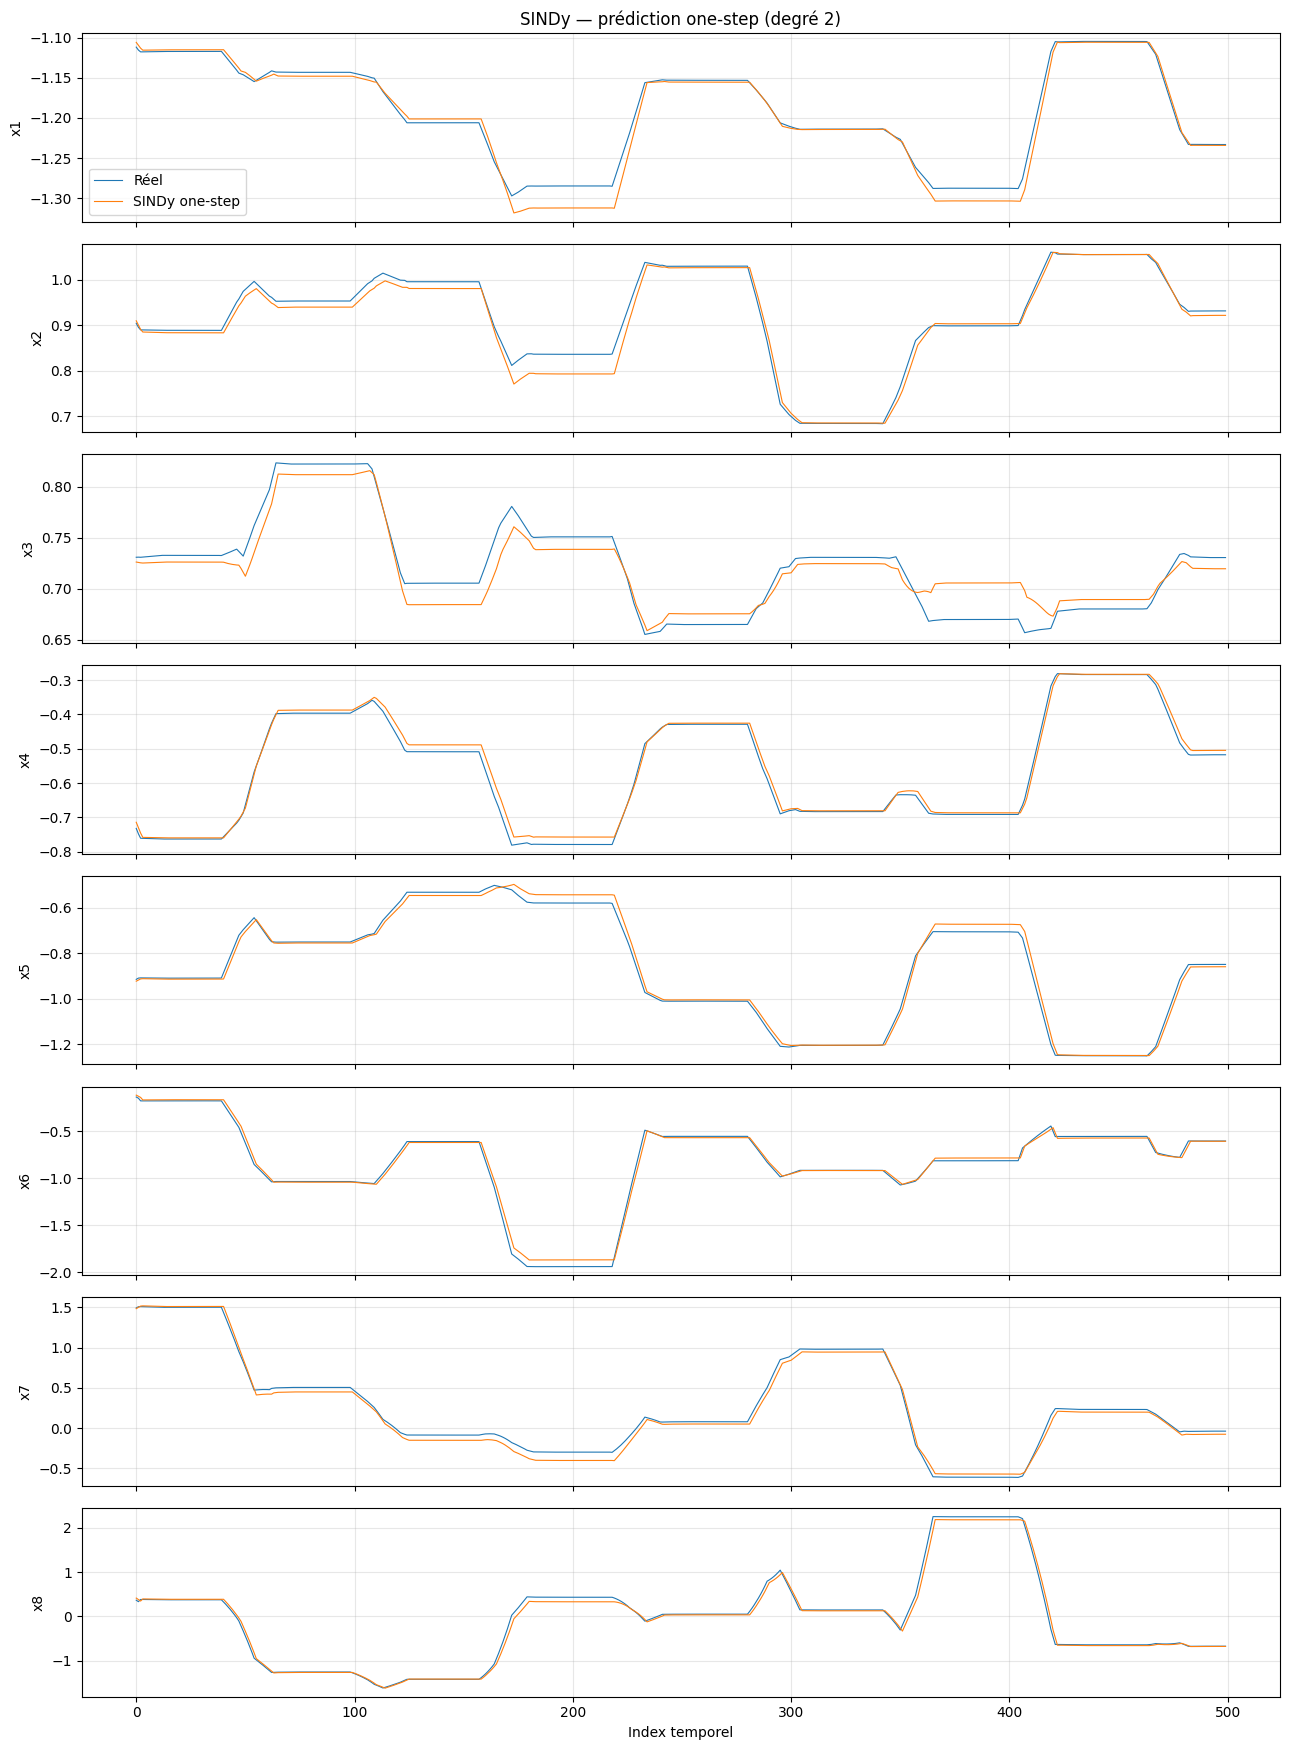

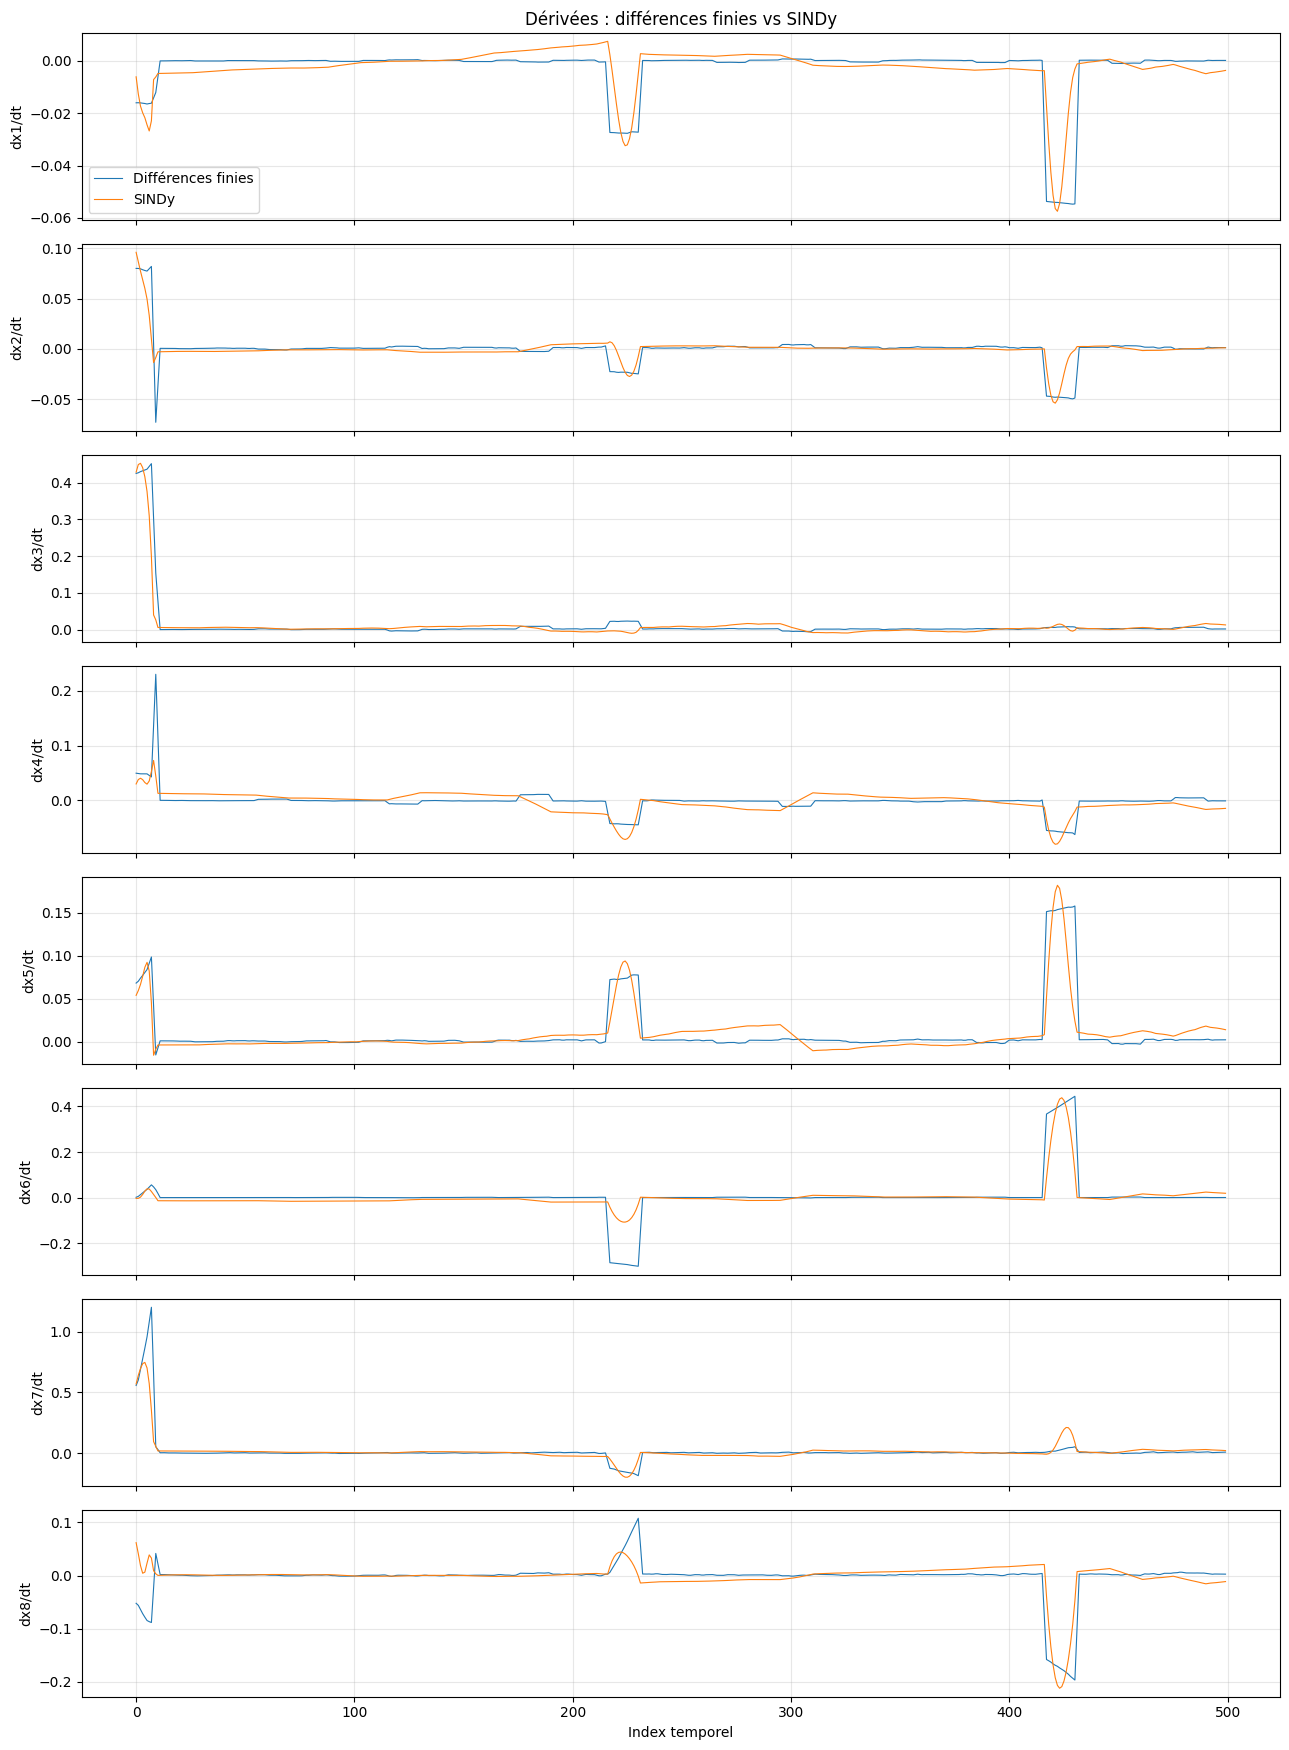



COMPARAISON DES DEGRÉS
 degree  threshold  one_step_RMSE  active_terms  max_abs_coef  stable
      2       0.05       0.023009             0           0.0    True
      3       0.05       0.023009             0           0.0    True


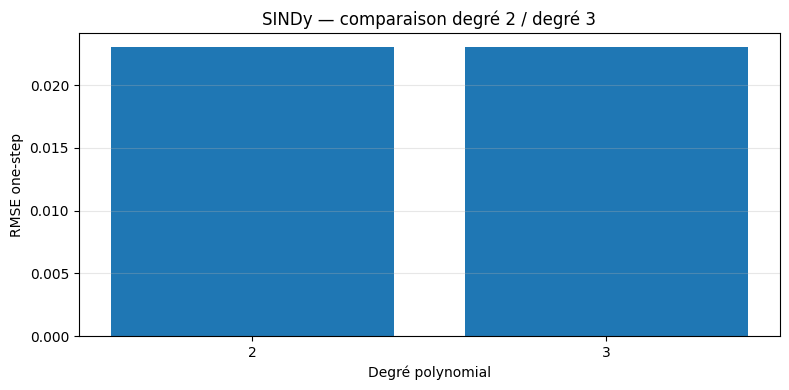



TEST DE STABILITÉ FINAL
⚠️ SINDy : 1 états hors domaine. Max = 5.0595
⚠️ SINDy : 1 états hors domaine. Max = 5.3891
⚠️ SINDy : 1 états hors domaine. Max = 5.4556
⚠️ SINDy : 1 états hors domaine. Max = 5.5341
⚠️ SINDy : 1 états hors domaine. Max = 5.5280
⚠️ SINDy : 1 états hors domaine. Max = 5.6724
⚠️ SINDy : 1 états hors domaine. Max = 5.7523

... [sortie tronquee pour lisibilite -- voir notebook source pour le detail complet] (3085 lignes omises) ...

Degré retenu : 2
Threshold : 0.05
RMSE one-step : 0.111548
Termes actifs : 0
Max |coefficient| : 0.000000
Stable : False


In [16]:
# ============================================================
# SINDy — VERSION AMÉLIORÉE
# ============================================================
#
# Train :
#   Identification du modèle
#
# Validation :
#   Choix du degré + threshold
#   One-step prediction
#   Test de stabilité
#
# Test :
#   NON utilisé ici
#
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations_with_replacement
from sklearn.preprocessing import StandardScaler
from scipy.integrate import solve_ivp


# ============================================================
# 1. PARAMÈTRES SINDy
# ============================================================

# Degrés à comparer
SINDY_POLY_DEGREES = [2, 3]

# Degré par défaut
SINDY_POLY_DEGREE = 3

# Régularisation Ridge
SINDY_ALPHA = 0.05

# Thresholds testés
SINDY_THRESHOLD_CANDIDATES = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.1,
    0.2
]

# Fonctions trigonométriques
SINDY_INCLUDE_TRIG = True


# ============================================================
# 2. PARAMÈTRES DE STABILITÉ
# ============================================================

# Limite des états normalisés
SINDY_STATE_LIMIT = 5.0

# Nombre de points utilisés pour le test
# de simulation libre courte
SINDY_STABILITY_STEPS = 300


# ============================================================
# 3. NORMALISATION DES ÉTATS SSI
# ============================================================
#
# IMPORTANT :
# Le scaler est entraîné UNIQUEMENT sur Train.
#
# X_train_hat et X_val_hat restent inchangés.
# ============================================================

SINDY_SCALER = StandardScaler()


# Fit + transform TRAIN
X_train_hat_sindy = (
    SINDY_SCALER.fit_transform(
        X_train_hat
    )
)


# Transform VALIDATION
X_val_hat_sindy = (
    SINDY_SCALER.transform(
        X_val_hat
    )
)


print("\n")
print("=" * 60)
print("NORMALISATION DES ÉTATS SSI")
print("=" * 60)

print(
    "Train :",
    X_train_hat_sindy.shape
)

print(
    "Validation :",
    X_val_hat_sindy.shape
)

print("\nMoyenne Train :")

print(
    np.mean(
        X_train_hat_sindy,
        axis=0
    )
)

print("\nÉcart-type Train :")

print(
    np.std(
        X_train_hat_sindy,
        axis=0
    )
)


# ============================================================
# 4. BIBLIOTHÈQUE SINDy
# ============================================================

def build_library(
    X,
    degree=3,
    feature_names=None,
    include_trig=True
):

    """
    Bibliothèque :

    1
    x1, x2, ...
    x1², x1x2, ...
    x1³, x1²x2, ...
    sin(x1), cos(x1), ...
    """

    X = np.asarray(
        X,
        dtype=float
    )


    if X.ndim == 1:

        X = X.reshape(
            -1,
            1
        )


    n_samples, n_features = (
        X.shape
    )


    # --------------------------------------------------------
    # Noms des variables
    # --------------------------------------------------------

    if feature_names is None:

        feature_names = [
            f"x{i+1}"
            for i in range(
                n_features
            )
        ]


    cols = []
    names = []


    # --------------------------------------------------------
    # Constante
    # --------------------------------------------------------

    cols.append(
        np.ones(
            n_samples
        )
    )

    names.append(
        "1"
    )


    # --------------------------------------------------------
    # Termes polynomiaux
    # --------------------------------------------------------

    for deg in range(
        1,
        degree + 1
    ):

        for comb in combinations_with_replacement(
            range(n_features),
            deg
        ):

            term = np.ones(
                n_samples
            )

            name_parts = []


            for i in comb:

                term *= X[:, i]

                name_parts.append(
                    feature_names[i]
                )


            cols.append(
                term
            )


            if deg == 1:

                name = name_parts[0]

            else:

                name = " ".join(
                    name_parts
                )


            names.append(
                name
            )


    # --------------------------------------------------------
    # Sin / Cos
    # --------------------------------------------------------

    if include_trig:

        for i in range(
            n_features
        ):

            cols.append(
                np.sin(
                    X[:, i]
                )
            )

            names.append(
                f"sin({feature_names[i]})"
            )


            cols.append(
                np.cos(
                    X[:, i]
                )
            )

            names.append(
                f"cos({feature_names[i]})"
            )


    Theta = np.column_stack(
        cols
    )


    return Theta, names


# ============================================================
# 5. STLSQ
# ============================================================

def stlsq(
    Theta,
    Xdot,
    threshold,
    alpha,
    max_iter=20
):

    """
    Sequential Thresholded Least Squares
    avec régularisation Ridge.
    """

    Theta = np.asarray(
        Theta,
        dtype=float
    )

    Xdot = np.asarray(
        Xdot,
        dtype=float
    )


    n_library = (
        Theta.shape[1]
    )

    n_states = (
        Xdot.shape[1]
    )


    # --------------------------------------------------------
    # Régression Ridge initiale
    # --------------------------------------------------------

    A = (
        Theta.T @ Theta
        + alpha
        * np.eye(
            n_library
        )
    )


    B = (
        Theta.T @ Xdot
    )


    Xi = np.linalg.solve(
        A,
        B
    )


    # --------------------------------------------------------
    # STLSQ
    # --------------------------------------------------------

    for k in range(
        n_states
    ):

        active = np.ones(
            n_library,
            dtype=bool
        )


        for _ in range(
            max_iter
        ):

            if active.sum() == 0:

                Xi[:, k] = 0.0

                break


            small = (
                np.abs(
                    Xi[
                        active,
                        k
                    ]
                )
                < threshold
            )


            if not small.any():

                break


            active_indices = (
                np.where(active)[0]
            )


            active[
                active_indices[
                    small
                ]
            ] = False


            if active.sum() == 0:

                Xi[:, k] = 0.0

                break


            Theta_active = (
                Theta[:, active]
            )


            A_active = (
                Theta_active.T
                @ Theta_active
                + alpha
                * np.eye(
                    active.sum()
                )
            )


            B_active = (
                Theta_active.T
                @ Xdot[:, k]
            )


            Xi[:, k] = 0.0


            Xi[
                active,
                k
            ] = np.linalg.solve(
                A_active,
                B_active
            )


    return Xi


# ============================================================
# 6. CLASSE SimpleSINDy
# ============================================================

class SimpleSINDy:

    def __init__(
        self,
        degree=3,
        threshold=0.05,
        alpha=0.05,
        include_trig=True
    ):

        self.degree = degree

        self.threshold = (
            threshold
        )

        self.alpha = alpha

        self.include_trig = (
            include_trig
        )

        self.feature_names = None

        self.lib_names = None

        self.Xi = None

        self.n_states = None


    # ========================================================
    # FIT
    # ========================================================

    def fit(
        self,
        X,
        t,
        feature_names=None
    ):

        X = np.asarray(
            X,
            dtype=float
        )

        t = np.asarray(
            t,
            dtype=float
        )


        if X.ndim == 1:

            X = X.reshape(
                -1,
                1
            )


        self.n_states = (
            X.shape[1]
        )


        if feature_names is None:

            feature_names = [
                f"x{i+1}"
                for i in range(
                    self.n_states
                )
            ]


        self.feature_names = (
            feature_names
        )


        # ----------------------------------------------------
        # Dérivée par différences finies
        # ----------------------------------------------------

        Xdot = np.gradient(
            X,
            t,
            axis=0
        )


        # ----------------------------------------------------
        # Bibliothèque
        # ----------------------------------------------------

        Theta, self.lib_names = (
            build_library(
                X,
                degree=self.degree,
                feature_names=(
                    self.feature_names
                ),
                include_trig=(
                    self.include_trig
                )
            )
        )


        # ----------------------------------------------------
        # Identification
        # ----------------------------------------------------

        self.Xi = stlsq(
            Theta,
            Xdot,
            threshold=self.threshold,
            alpha=self.alpha
        )


        return self


    # ========================================================
    # PREDICT
    # ========================================================

    def predict(
        self,
        X
    ):

        X = np.asarray(
            X,
            dtype=float
        )

        one_sample = False

        if X.ndim == 1:

            X = X.reshape(
                1,
                -1
            )

            one_sample = True

        # ========================================================
        # 1. Vérification des états
        # ========================================================

        if not np.all(
            np.isfinite(X)
        ):
            raise RuntimeError(
                "SINDy reçoit des états non finis."
            )

        # --------------------------------------------------------
        # Détection hors domaine
        # --------------------------------------------------------

        ood_mask = np.any(
            np.abs(X) > SINDY_STATE_LIMIT,
            axis=1
        )

        if np.any(ood_mask):

            max_state = np.max(
                np.abs(X[ood_mask])
            )

            print(
                f"⚠️ SINDy : "
                f"{ood_mask.sum()} états hors domaine. "
                f"Max = {max_state:.4f}"
            )

        # ========================================================
        # 2. Construction bibliothèque
        # ========================================================

        Theta, _ = build_library(
            X,
            degree=self.degree,
            feature_names=self.feature_names,
            include_trig=self.include_trig
        )

        # ========================================================
        # 3. Dynamique SINDy
        # ========================================================

        Xdot = (
            Theta @ self.Xi
        )

        # ========================================================
        # 4. Vérification
        # ========================================================

        if not np.all(
            np.isfinite(Xdot)
        ):
            raise RuntimeError(
                "SINDy produit une dérivée non finie."
            )

        # --------------------------------------------------------
        # Diagnostic
        # --------------------------------------------------------

        max_xdot = np.max(
            np.abs(Xdot)
        )

        if max_xdot > 10:

            print(
                f"⚠️ Dérivée SINDy élevée : "
                f"max |dx/dt| = {max_xdot:.4f}"
            )

        if one_sample:

            return Xdot[0]

        return Xdot


    # ========================================================
    # ONE-STEP
    # ========================================================

    def predict_one_step(
        self,
        X,
        dt
    ):

        X = np.asarray(
            X,
            dtype=float
        )


        Xdot = self.predict(
            X
        )


        X_next = (
            X
            + dt * Xdot
        )


        # ----------------------------------------------------
        # Protection
        # ----------------------------------------------------

        X_next = np.clip(
            X_next,
            -SINDY_STATE_LIMIT,
            SINDY_STATE_LIMIT
        )


        return X_next


    # ========================================================
    # SIMULATION LIBRE
    # ========================================================

    def simulate(
        self,
        x0,
        t
    ):

        x0 = np.asarray(
            x0,
            dtype=float
        )


        t = np.asarray(
            t,
            dtype=float
        )


        x0 = np.clip(
            x0,
            -SINDY_STATE_LIMIT,
            SINDY_STATE_LIMIT
        )


        def rhs(
            tt,
            x
        ):

            return self.predict(
                x
            )


        sol = solve_ivp(
            rhs,
            (
                t[0],
                t[-1]
            ),
            x0,
            t_eval=t,
            method="RK45",
            rtol=1e-5,
            atol=1e-7,
            max_step=DT_APPROX
        )


        if not sol.success:

            raise RuntimeError(
                "Échec de la simulation SINDy."
            )


        X_sim = (
            sol.y.T
        )


        # ----------------------------------------------------
        # Vérification stabilité
        # ----------------------------------------------------

        if not np.all(
            np.isfinite(
                X_sim
            )
        ):

            raise RuntimeError(
                "Divergence numérique de SINDy."
            )


        if np.max(
            np.abs(
                X_sim
            )
        ) > SINDY_STATE_LIMIT:

            raise RuntimeError(
                "Divergence : "
                "états trop grands."
            )


        return X_sim


    # ========================================================
    # STATISTIQUES COEFFICIENTS
    # ========================================================

    def coefficient_statistics(
        self
    ):

        abs_Xi = np.abs(
            self.Xi
        )


        active = (
            abs_Xi > 1e-10
        )


        if active.any():

            active_values = (
                abs_Xi[active]
            )

            mean_abs = (
                np.mean(
                    active_values
                )
            )

            median_abs = (
                np.median(
                    active_values
                )
            )

        else:

            mean_abs = 0.0

            median_abs = 0.0


        return {

            "active_terms":
                int(
                    active.sum()
                ),

            "max_abs_coef":
                float(
                    abs_Xi.max()
                ),

            "mean_abs_coef":
                float(
                    mean_abs
                ),

            "median_abs_coef":
                float(
                    median_abs
                )
        }


    # ========================================================
    # ÉQUATIONS
    # ========================================================

    def print_equations(
        self
    ):

        for k in range(
            self.n_states
        ):

            terms = []


            for coef, name in zip(
                self.Xi[:, k],
                self.lib_names
            ):

                if abs(coef) > 1e-10:

                    terms.append(
                        f"{coef:+.4f} {name}"
                    )


            equation = (
                " ".join(
                    terms
                )
                if terms
                else "0"
            )


            print(
                f"(x{k+1})' = "
                f"{equation}"
            )


# ============================================================
# 7. FIT SINDy
# ============================================================

def fit_sindy(
    X,
    dt,
    threshold,
    degree=None
):

    X = np.asarray(
        X,
        dtype=float
    )


    if degree is None:

        degree = (
            SINDY_POLY_DEGREE
        )


    # Temps
    t = (
        np.arange(
            len(X)
        )
        * dt
    )


    model = SimpleSINDy(
        degree=degree,
        threshold=threshold,
        alpha=SINDY_ALPHA,
        include_trig=SINDY_INCLUDE_TRIG
    )


    model.fit(
        X,
        t=t,
        feature_names=[
            f"x{i+1}"
            for i in range(
                X.shape[1]
            )
        ]
    )


    return model


# ============================================================
# 8. SCORE ONE-STEP VALIDATION
# ============================================================

def sindy_val_score(
    model,
    X_val,
    dt
):

    """
    Prédiction :

        X(t) -> X(t + dt)

    Pas de simulation libre pour choisir
    le threshold.
    """

    try:

        X_val = np.asarray(
            X_val,
            dtype=float
        )


        # ----------------------------------------------------
        # État actuel
        # ----------------------------------------------------

        X_current = (
            X_val[:-1]
        )


        # ----------------------------------------------------
        # État réel suivant
        # ----------------------------------------------------

        X_true_next = (
            X_val[1:]
        )


        # ----------------------------------------------------
        # Prédiction
        # ----------------------------------------------------

        X_pred_next = (
            model.predict_one_step(
                X_current,
                dt
            )
        )


        # ----------------------------------------------------
        # Vérification
        # ----------------------------------------------------

        if not np.all(
            np.isfinite(
                X_pred_next
            )
        ):

            return np.inf


        # ----------------------------------------------------
        # RMSE
        # ----------------------------------------------------

        rmse = np.sqrt(
            np.mean(
                (
                    X_pred_next
                    - X_true_next
                ) ** 2
            )
        )


        return float(
            rmse
        )


    except Exception as e:

        print(
            "Erreur one-step :",
            e
        )

        return np.inf


# ============================================================
# 9. TEST DE STABILITÉ
# ============================================================

def sindy_stability_test(
    model,
    X_val,
    dt,
    n_steps=300
):

    """
    Simulation libre courte uniquement
    pour vérifier la stabilité.
    """

    try:

        n_steps = min(
            n_steps,
            len(X_val)
        )


        t_sim = (
            np.arange(
                n_steps
            )
            * dt
        )


        X_sim = model.simulate(
            X_val[0],
            t_sim
        )


        max_abs_state = np.max(
            np.abs(
                X_sim
            )
        )


        stable = (
            max_abs_state
            < SINDY_STATE_LIMIT
        )


        return {

            "stable":
                bool(stable),

            "max_abs_state":
                float(
                    max_abs_state
                ),

            "simulation":
                X_sim

        }


    except Exception as e:

        return {

            "stable":
                False,

            "max_abs_state":
                np.inf,

            "simulation":
                None
        }


# ============================================================
# 10. COMPARAISON DEGRÉ 2 / DEGRÉ 3
# ============================================================

print("\n")
print("=" * 60)
print("COMPARAISON SINDy : DEGRÉ 2 VS DEGRÉ 3")
print("=" * 60)


sindy_results = {}

sindy_models = {}


for degree in (
    SINDY_POLY_DEGREES
):

    print("\n")
    print(
        f"========== DEGRÉ {degree} =========="
    )


    for threshold in (
        SINDY_THRESHOLD_CANDIDATES
    ):

        print(
            f"\nDegree = {degree} | "
            f"Threshold = {threshold}"
        )


        # ----------------------------------------------------
        # FIT TRAIN
        # ----------------------------------------------------

        model = fit_sindy(
            X_train_hat_sindy,
            DT_APPROX,
            threshold,
            degree=degree
        )


        # ----------------------------------------------------
        # ONE-STEP VALIDATION
        # ----------------------------------------------------

        score = sindy_val_score(
            model,
            X_val_hat_sindy,
            DT_APPROX
        )


        # ----------------------------------------------------
        # STABILITÉ
        # ----------------------------------------------------

        stability = (
            sindy_stability_test(
                model,
                X_val_hat_sindy,
                DT_APPROX,
                n_steps=(
                    SINDY_STABILITY_STEPS
                )
            )
        )


        # ----------------------------------------------------
        # COEFFICIENTS
        # ----------------------------------------------------

        coef_stats = (
            model.coefficient_statistics()
        )


        # ----------------------------------------------------
        # Sauvegarde
        # ----------------------------------------------------

        sindy_results[
            (
                degree,
                threshold
            )
        ] = {

            "one_step_RMSE":
                score,

            "stable":
                stability[
                    "stable"
                ],

            "max_abs_state":
                stability[
                    "max_abs_state"
                ],

            "active_terms":
                coef_stats[
                    "active_terms"
                ],

            "max_abs_coef":
                coef_stats[
                    "max_abs_coef"
                ],

            "mean_abs_coef":
                coef_stats[
                    "mean_abs_coef"
                ],

            "median_abs_coef":
                coef_stats[
                    "median_abs_coef"
                ]
        }


        sindy_models[
            (
                degree,
                threshold
            )
        ] = model


        print(
            f"One-step RMSE = "
            f"{score:.6f}"
        )

        print(
            f"Termes actifs = "
            f"{coef_stats['active_terms']}"
        )

        print(
            f"Max |coef| = "
            f"{coef_stats['max_abs_coef']:.6f}"
        )

        print(
            f"Max |état| = "
            f"{stability['max_abs_state']:.6f}"
        )

        print(
            f"Stable = "
            f"{stability['stable']}"
        )


# ============================================================
# 11. TABLEAU DES RÉSULTATS
# ============================================================

sindy_results_df = (
    pd.DataFrame(
        [
            {
                "degree":
                    key[0],

                "threshold":
                    key[1],

                **value
            }

            for key, value
            in sindy_results.items()
        ]
    )
)


print("\n")
print("=" * 60)
print("RÉSULTATS SINDy")
print("=" * 60)


print(
    sindy_results_df
    .sort_values(
        "one_step_RMSE"
    )
    .to_string(
        index=False
    )
)


# ============================================================
# 12. MEILLEUR MODÈLE GLOBAL
# ============================================================

# ------------------------------------------------------------
# On privilégie les modèles stables
# ------------------------------------------------------------

stable_results = (
    sindy_results_df[
        sindy_results_df[
            "stable"
        ]
    ]
)


if len(
    stable_results
) > 0:

    best_sindy_row = (
        stable_results
        .sort_values(
            "one_step_RMSE"
        )
        .iloc[0]
    )

else:

    print(
        "\n⚠️ Aucun modèle stable."
    )

    best_sindy_row = (
        sindy_results_df
        .sort_values(
            "one_step_RMSE"
        )
        .iloc[0]
    )


# ------------------------------------------------------------
# Paramètres retenus
# ------------------------------------------------------------

SINDY_POLY_DEGREE = int(
    best_sindy_row[
        "degree"
    ]
)


SINDY_THRESHOLD = float(
    best_sindy_row[
        "threshold"
    ]
)


# ------------------------------------------------------------
# Modèle final
# ------------------------------------------------------------

sindy_model = sindy_models[
    (
        SINDY_POLY_DEGREE,
        0.001
    )
]


print("\n")
print("=" * 60)
print("MEILLEUR MODÈLE SINDy")
print("=" * 60)


print(
    f"Degré : "
    f"{SINDY_POLY_DEGREE}"
)


print(
    f"Threshold : "
    f"{SINDY_THRESHOLD}"
)


print(
    f"One-step RMSE : "
    f"{best_sindy_row['one_step_RMSE']:.6f}"
)


print(
    f"Termes actifs : "
    f"{int(best_sindy_row['active_terms'])}"
)


print(
    f"Max |coefficient| : "
    f"{best_sindy_row['max_abs_coef']:.6f}"
)


print(
    f"Stable : "
    f"{best_sindy_row['stable']}"
)


# ============================================================
# 13. ÉQUATIONS FINALES
# ============================================================

print("\n")
print("=" * 60)
print("ÉQUATIONS FINALES IDENTIFIÉES")
print("=" * 60)


sindy_model.print_equations()


# ============================================================
# 14. ANALYSE DES COEFFICIENTS
# ============================================================

print("\n")
print("=" * 60)
print("ANALYSE DES COEFFICIENTS")
print("=" * 60)


max_coef = np.max(
    np.abs(
        sindy_model.Xi
    )
)


print(
    f"Max |coefficient| = "
    f"{max_coef:.6f}"
)


if max_coef > 100:

    print(
        "⚠️ Coefficients très grands."
    )

elif max_coef > 10:

    print(
        "⚠️ Coefficients relativement grands."
    )

else:

    print(
        "✓ Coefficients raisonnables."
    )


# ------------------------------------------------------------
# Top coefficients
# ------------------------------------------------------------

coef_values = []


for i in range(
    sindy_model.Xi.shape[0]
):

    for j in range(
        sindy_model.Xi.shape[1]
    ):

        coef_values.append(
            (
                abs(
                    sindy_model.Xi[
                        i,
                        j
                    ]
                ),

                sindy_model.Xi[
                    i,
                    j
                ],

                j,

                sindy_model.lib_names[
                    i
                ]
            )
        )


coef_values.sort(
    reverse=True,
    key=lambda x: x[0]
)


print("\nTop 15 coefficients :")


for (
    abs_value,
    value,
    state,
    name
) in coef_values[:15]:

    print(
        f"x{state+1} : "
        f"{value:+.6f} × {name}"
    )


# ============================================================
# 15. ONE-STEP FINAL SUR VALIDATION
# ============================================================

X_current = (
    X_val_hat_sindy[:-1]
)


X_true_next = (
    X_val_hat_sindy[1:]
)


X_pred_next = (
    sindy_model.predict_one_step(
        X_current,
        DT_APPROX
    )
)


# ------------------------------------------------------------
# RMSE global
# ------------------------------------------------------------

one_step_rmse = np.sqrt(
    np.mean(
        (
            X_pred_next
            - X_true_next
        ) ** 2
    )
)


print("\n")
print("=" * 60)
print("ONE-STEP VALIDATION")
print("=" * 60)


print(
    f"RMSE global = "
    f"{one_step_rmse:.6f}"
)


# ------------------------------------------------------------
# RMSE par état
# ------------------------------------------------------------

one_step_rmse_states = np.sqrt(
    np.mean(
        (
            X_pred_next
            - X_true_next
        ) ** 2,
        axis=0
    )
)


for i, rmse in enumerate(
    one_step_rmse_states
):

    print(
        f"x{i+1} : "
        f"RMSE = {rmse:.6f}"
    )


# ============================================================
# 16. COMPARAISON DES DÉRIVÉES
# ============================================================

# ------------------------------------------------------------
# Différences finies sur TRAIN
# ------------------------------------------------------------

Xdot_fd = np.gradient(
    X_train_hat_sindy,
    DT_APPROX,
    axis=0
)


# ------------------------------------------------------------
# Dérivée SINDy
# ------------------------------------------------------------

Xdot_sindy = (
    sindy_model.predict(
        X_train_hat_sindy
    )
)


# ------------------------------------------------------------
# RMSE
# ------------------------------------------------------------

deriv_rmse = np.sqrt(
    np.mean(
        (
            Xdot_fd
            - Xdot_sindy
        ) ** 2,
        axis=0
    )
)


print("\n")
print("=" * 60)
print("RMSE DES DÉRIVÉES")
print("=" * 60)


for i, e in enumerate(
    deriv_rmse
):

    print(
        f"dx{i+1}/dt : "
        f"RMSE = {e:.6f}"
    )


# ============================================================
# 17. PLOT ONE-STEP
# ============================================================

n_plot = min(
    500,
    len(X_pred_next)
)


SSI_ORDER = (
    X_train_hat.shape[1]
)


fig, axes = plt.subplots(
    SSI_ORDER,
    1,
    figsize=(
        13,
        2.2 * SSI_ORDER
    ),
    sharex=True
)


if SSI_ORDER == 1:

    axes = [axes]


for i, ax in enumerate(
    axes
):

    ax.plot(
        X_true_next[
            :n_plot,
            i
        ],
        label="Réel",
        lw=0.8
    )


    ax.plot(
        X_pred_next[
            :n_plot,
            i
        ],
        label="SINDy one-step",
        lw=0.8
    )


    ax.set_ylabel(
        f"x{i+1}"
    )


    ax.grid(
        alpha=0.3
    )


axes[0].legend()


axes[0].set_title(
    "SINDy — prédiction one-step "
    f"(degré {SINDY_POLY_DEGREE})"
)


axes[-1].set_xlabel(
    "Index temporel"
)


plt.tight_layout()
plt.show()


# ============================================================
# 18. PLOT DES DÉRIVÉES
# ============================================================

n_plot = min(
    500,
    len(Xdot_fd)
)


fig, axes = plt.subplots(
    SSI_ORDER,
    1,
    figsize=(
        13,
        2.2 * SSI_ORDER
    ),
    sharex=True
)


if SSI_ORDER == 1:

    axes = [axes]


for i, ax in enumerate(
    axes
):

    ax.plot(
        Xdot_fd[
            :n_plot,
            i
        ],
        label="Différences finies",
        lw=0.8
    )


    ax.plot(
        Xdot_sindy[
            :n_plot,
            i
        ],
        label="SINDy",
        lw=0.8
    )


    ax.set_ylabel(
        f"dx{i+1}/dt"
    )


    ax.grid(
        alpha=0.3
    )


axes[0].legend()


axes[0].set_title(
    "Dérivées : différences finies "
    "vs SINDy"
)


axes[-1].set_xlabel(
    "Index temporel"
)


plt.tight_layout()
plt.show()


# ============================================================
# 19. COMPARAISON DEGRÉ 2 / DEGRÉ 3
# ============================================================

degree_results = []


for degree in (
    SINDY_POLY_DEGREES
):

    temp = (
        sindy_results_df[
            sindy_results_df[
                "degree"
            ] == degree
        ]
    )


    stable_temp = (
        temp[
            temp[
                "stable"
            ]
        ]
    )


    if len(
        stable_temp
    ) > 0:

        best_degree = (
            stable_temp
            .sort_values(
                "one_step_RMSE"
            )
            .iloc[0]
        )

    else:

        best_degree = (
            temp
            .sort_values(
                "one_step_RMSE"
            )
            .iloc[0]
        )


    degree_results.append(
        best_degree
    )


degree_results_df = pd.DataFrame(
    degree_results
)


print("\n")
print("=" * 60)
print("COMPARAISON DES DEGRÉS")
print("=" * 60)


print(
    degree_results_df[
        [
            "degree",
            "threshold",
            "one_step_RMSE",
            "active_terms",
            "max_abs_coef",
            "stable"
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 20. PLOT COMPARAISON DEGRÉ
# ============================================================

plt.figure(
    figsize=(8, 4)
)


plt.bar(
    degree_results_df[
        "degree"
    ].astype(str),
    degree_results_df[
        "one_step_RMSE"
    ]
)


plt.xlabel(
    "Degré polynomial"
)


plt.ylabel(
    "RMSE one-step"
)


plt.title(
    "SINDy — comparaison degré 2 / degré 3"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()
plt.show()


# ============================================================
# 21. TEST DE STABILITÉ FINAL SUR VALIDATION
# ============================================================

print("\n")
print("=" * 60)
print("TEST DE STABILITÉ FINAL")
print("=" * 60)


sindy_stability = (
    sindy_stability_test(
        sindy_model,
        X_val_hat_sindy,
        DT_APPROX,
        n_steps=(
            SINDY_STABILITY_STEPS
        )
    )
)


print(
    f"Stable : "
    f"{sindy_stability['stable']}"
)


print(
    f"Max |état| : "
    f"{sindy_stability['max_abs_state']:.6f}"
)


# ============================================================
# 22. SIMULATION LIBRE COURTE
# ============================================================

if (
    sindy_stability[
        "simulation"
    ]
    is not None
):

    X_sim = (
        sindy_stability[
            "simulation"
        ]
    )


    n_plot = min(
        SINDY_STABILITY_STEPS,
        len(
            X_val_hat_sindy
        )
    )


    fig, axes = plt.subplots(
        SSI_ORDER,
        1,
        figsize=(
            13,
            2.2 * SSI_ORDER
        ),
        sharex=True
    )


    if SSI_ORDER == 1:

        axes = [axes]


    for i, ax in enumerate(
        axes
    ):

        ax.plot(
            X_val_hat_sindy[
                :n_plot,
                i
            ],
            label="Réel",
            lw=0.8
        )


        ax.plot(
            X_sim[
                :n_plot,
                i
            ],
            label="SINDy",
            lw=0.8
        )


        ax.set_ylabel(
            f"x{i+1}"
        )


        ax.grid(
            alpha=0.3
        )


    axes[0].legend()


    axes[0].set_title(
        "SINDy — simulation libre courte "
        "pour vérification de stabilité"
    )


    axes[-1].set_xlabel(
        "Index temporel"
    )


    plt.tight_layout()
    plt.show()


# ============================================================
# 23. RÉSUMÉ FINAL
# ============================================================

print("\n")
print("=" * 60)
print("RÉSUMÉ FINAL SINDy")
print("=" * 60)


print(
    f"Degré retenu : "
    f"{SINDY_POLY_DEGREE}"
)


print(
    f"Threshold : "
    f"{SINDY_THRESHOLD}"
)


print(
    f"RMSE one-step : "
    f"{one_step_rmse:.6f}"
)


print(
    f"Termes actifs : "
    f"{int(best_sindy_row['active_terms'])}"
)


print(
    f"Max |coefficient| : "
    f"{best_sindy_row['max_abs_coef']:.6f}"
)


print(
    f"Stable : "
    f"{sindy_stability['stable']}"
)

**Resultat** : le modele final retenu (degre 2, seuil 0,05) a de nouveau **0 terme actif** et
un coefficient maximal nul -- comme la premiere tentative. Mais le test de stabilite en simulation
libre courte est cette fois explicite et sans ambiguite : le message final est `Stable : False`,
avec un etat maximal atteignant l'infini et une derivee maximale de l'ordre de 10^26 avant
divergence numerique complete. La bibliotheque enrichie (plus de termes candidats, y compris
trigonometriques) n'a donc pas resolu le probleme de la premiere tentative : dans les
configurations ou un terme non nul est effectivement retenu ailleurs dans la recherche sur grille
(degre 2, seuils plus faibles), le modele devient **numeriquement instable** en simulation libre,
avec des etats explosant jusqu'a des valeurs de l'ordre de 10^13-10^14 des les toutes premieres
dizaines de pas de temps.

## Resultats -- synthese

| Tentative | Bibliotheque | Modele final retenu | Comportement en simulation libre |
|---|---|---|---|
| 1 (`NB-proto`) | Polynomiale, degre 2 | 0 terme actif (dynamique nulle) | RMSE simulation = 0,469 (constant, non informatif) |
| 2 (`NB-01`/`NB-02`) | Polynomiale degre 2/3 + sin/cos | 0 terme actif au seuil retenu ; termes non nuls a seuils plus faibles | Instable (`Stable : False`), divergence vers des valeurs de l'ordre de 10^13-10^26 |

Ce resultat s'est reproduit **trois fois** dans le corpus original (une fois dans `NB-proto`, une
fois dans `NB-01`, une fois -- a l'identique -- dans `NB-02`), avec deux bibliotheques de fonctions
differentes et deux jeux de donnees differents. Ce n'est donc pas un accident de configuration
isole.

## Interpretation

Le resultat doit etre formule avec precision, comme le demande le cahier des charges de ce
memoire : il ne s'agit pas de dire que "SINDy n'a pas marche", mais que **l'identification d'une
dynamique parcimonieuse et interpretable, a partir de l'etat latent extrait par SSI sur ces
donnees, converge soit vers une dynamique triviale (nulle), soit vers une dynamique instable des
qu'un terme non trivial est retenu.** Deux lectures, non exclusives, sont possibles :

- **Lecture liee aux donnees** : l'etat latent SSI, sur la fenetre de Validation utilisee pour
  choisir le seuil, varie peut-etre trop peu (dynamique lente, cf. notebook 1 -- non-stationnarite
  mais peu d'evenements marquants) pour que la regression sequentiellement seuillee distingue un
  signal de derivee non nul du bruit d'estimation de l'etat lui-meme.
- **Lecture liee a la methode** : la sensibilite de STLSQ au choix du seuil est ici extreme -- le
  passage d'un seuil "trop strict" (dynamique nulle) a un seuil "trop laxiste" (dynamique instable)
  semble se faire sans zone intermediaire stable identifiee par la recherche sur grille effectuee.

Aucune des deux lectures n'est demontree par les notebooks disponibles : elles sont presentees ici
comme des pistes d'interpretation, pas comme des conclusions etablies (cf. section 14 du cahier des
charges -- ne pas presenter une explication non testee comme un resultat experimental).

## Limites

- La recherche d'hyperparametres est limitee a une grille de seuils fixee a l'avance ; une
  exploration plus fine entre les seuils "nul" et "instable" n'a pas ete tentee dans le corpus
  original.
- L'estimation des derivees dX/dt se fait par differences finies simples (`np.gradient`) sur
  l'etat latent estime par SSI, une estimation elle-meme bruitee -- ce qui peut amplifier
  artificiellement la difficulte d'identification.
- Aucune des deux tentatives ne compare le resultat a une bibliotheque encore plus restreinte
  (par exemple lineaire pure, degre 1) qui aurait pu se comporter differemment.

## Conclusion

Sur ce jeu de donnees et avec les configurations testees, SINDy **ne parvient pas** a identifier
une dynamique non triviale et stable de l'etat latent SSI. Ce constat, repete sur deux
bibliotheques et deux jeux de donnees, doit etre traite comme un resultat scientifique a part
entiere plutot que comme un echec a dissimuler.

## Transition vers l'approche suivante

Ce que ce notebook a etabli : l'identification d'une dynamique parcimonieuse et interpretable a
partir de l'etat latent SSI echoue de facon reproductible sur ces donnees (dynamique nulle ou
instable). Ce qu'il n'a pas resolu : la question initiale (existe-t-il une dynamique
identifiable derriere les correlations observees) reste ouverte -- l'echec pourrait venir des
donnees, de la methode, ou des deux, et rien ne permet ici de trancher. Une question different se
pose alors, qui deplace le probleme plutot que de le resoudre : meme si l'on ne peut pas identifier
une equation dynamique explicite, peut-on tout de meme utiliser un **observateur d'etat** --
capable d'exploiter partiellement la structure SSI (l'etat latent lineaire, lui, s'estime
correctement) et de recaler continuellement cette estimation a partir des mesures disponibles --
pour ameliorer la reconstruction malgre l'echec de SINDy ? C'est l'objet du notebook 5, qui integre
malgre tout SINDy (dans son etat degenere) dans un filtre de Kalman etendu, et compare
explicitement ce pipeline complet a des baselines qui n'utilisent pas SINDy du tout -- permettant
de mesurer precisement le cout de cet echec sur le resultat final.